
**Цель задания:** 
Спроектировать и реализовать объектную модель учёта банковских операций с опорой на материалы тем 1–5 (файлы, datetime, pandas, регулярные выражения, ООП).


Контекст
Нужна небольшая модель учёта банковских счетов: расчётный и сберегательный счёт. Система должна вести историю операций, валидировать входные данные, отличать успешные операции от отклонённых и давать простую аналитику.

Решение оформите в объектно-ориентированном стиле. Опирайтесь на материалы тем 1–5. Конкретную структуру классов, имена методов и способ хранения данных выбираете вы - важно, чтобы поведение системы соответствовало правилам ниже и чтобы демонстрация в ноутбуке это подтверждала.


**Задание 1.**
Реализуйте модель банковского счёта, которая не только меняет баланс, но и ведёт детальную историю действий.

Этап 1.
Правила
1. Счёт открывается с именем владельца и начальным балансом. Начальный баланс не может быть отрицательным (по умолчанию - 0).

2. Номер счёта формируется автоматически в формате ACC-XXXX, где XXXX - порядковый номер. Счётчик номеров начинается с 1000. Номера счетов должны быть уникальными.

3. Поддерживаются операции пополнения и снятия:

- сумма операции должна быть положительной

- некорректная сумма приводит к исключению

- при успехе баланс обновляется, в историю добавляется запись со статусом успешной операции

- если средств недостаточно, баланс не меняется, но попытка обязательно фиксируется в истории со статусом неуспешной операции

4. Каждая запись истории — структурированные данные. Минимум полей: тип операции (deposit / withdraw), сумма, дата и время, баланс после операции, статус (success / fail). Для даты и времени используйте модуль datetime.

5. Должна быть возможность узнать текущий баланс и получить историю операций в удобном для чтения виде.


Демонстрация

В ноутбуке покажите:

- создание счёта

- несколько успешных пополнений и снятий

- хотя бы одну неуспешную попытку снятия

- вывод баланса и истории.

Этап 2.
По истории операций постройте линейный график изменения баланса во времени (ось X - время операции, ось Y - баланс после операции). У графика должны быть заголовок и подписи осей.


**Задание 2. Разные типы счетов и аналитика**

Расчётный и сберегательный счета должны отражать общее поведение учёта операций, но отличаться правилами.

Правила
Расчётный счёт - базовые пополнение и снятие без дополнительных ограничений на долю снимаемой суммы.

Сберегательный счёт: умеет начислять проценты на текущий остаток (ставку задаёт вызывающий код, например 7%); нельзя снять больше 50% текущего баланса; нарушающая правило попытка не меняет баланс и фиксируется в истории как неуспешная.

У каждого типа счёта должен быть различимый тип (чтобы по объекту/данным было понятно, расчётный это счёт или сберегательный).

Валидация имени владельца: формат «Имя Фамилия», слова с заглавной буквы, кириллица или латиница. Иначе - исключение. Для проверки используйте регулярные выражения.

Аналитика по истории: возможность получить последние N крупных успешных операций (порог «крупности» и N задаёт вызывающий код).

Демонстрация
В ноутбуке покажите:

- создание расчётного и сберегательного счета;

- покажите начисление процентов на сберегательном;

- покажите отклонение снятия сверх 50% на сберегательном;

- покажите выборку последних крупных операций;

- покажите реакцию на некорректное имя владельца и/или некорректную сумму.

**Дополнительное задание. 
Перевод между счетами**
Добавьте возможность перевода средств с одного счёта на другой:

- при успехе сумма списывается у отправителя и зачисляется получателю;

- если списание у отправителя невозможно (недостаточно средств или сработали ограничения сберегательного счёта), баланс получателя не меняется;

- в историях обоих счетов перевод должен быть различим (например, общий идентификатор перевода, связанные записи или иной явный признак - способ выбираете вы).

Этот пункт не обязателен, но без него сложно претендовать на верхнюю часть шкалы: он показывает, насколько согласовано поведение разных счетов и насколько аккуратно продуманы связанные операции.

## Задание 1

In [1]:
import re
import time
import math
from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt

**Сумма операции должна быть положительной** и некорректная сумма приводит к исключению, напишем отдельную функцию, которая это проверяет:

In [2]:
def is_number(x):
    return isinstance(x, (int, float)) and not isinstance(x, bool) and math.isfinite(x)


def check_amount(amount):
    if not is_number(amount) or amount <= 0:
        raise ValueError("Сумма должна быть положительным числом")

**Валидация имени владельца:** формат «Имя Фамилия», слова с заглавной буквы, кириллица или латиница. Иначе - исключение. 

In [3]:
WORD = r"([A-Z][a-z]+|[А-ЯЁ][а-яё]+)"      
NAME_PATTERN = WORD + " " + WORD           

def check_owner(owner):
    if not isinstance(owner, str) or re.fullmatch(NAME_PATTERN, owner) is None:
        raise ValueError("Имя владельца должно быть в формате 'Имя Фамилия' (с заглавных букв)")

**Проверка начального баланса**

In [4]:
def check_initial_balance(balance):
    if not is_number(balance):
        raise ValueError("Начальный баланс должен быть числом")
    if balance < 0:
        raise ValueError("Начальный баланс не может быть отрицательным")

In [5]:
class BankAccount:
    account_type = "checking"                 
    allowed_types = ["deposit", "withdraw"]   
    counter = 1000                            
    transfer_counter = 1                      
    
    # Создание счета
    def __init__(self, owner, balance=0):
        check_owner(owner)
        if not isinstance(balance, (int, float)) or balance < 0:
            raise ValueError("Начальный баланс не может быть отрицательным")
        self.owner = owner
        self.balance = balance
        self.initial_balance = balance      
        self.number = "ACC-" + str(BankAccount.counter)
        BankAccount.counter += 1             
        self.history = []                   
    
    # Добавление записи об операции в таблицу
    def _add_record(self, op_type, amount, status, dt=None, transfer_id=None):
        if dt is None:
            dt = datetime.now()              
        record = {
            "type": op_type,                 
            "amount": amount,
            "datetime": dt,
            "balance_after": self.balance,  
            "status": status,                
            "transfer_id": transfer_id,       #None, если это не перевод
        }
        self.history.append(record)

    # Правило снятия
    def can_withdraw(self, amount):
        return amount <= self.balance

    # Операции
    def deposit(self, amount, transfer_id=None):
        check_amount(amount)                 
        self.balance = round(self.balance + amount, 2)
        self._add_record("deposit", amount, "success", transfer_id=transfer_id)
        return True

    def withdraw(self, amount, transfer_id=None):
        check_amount(amount)
        if self.can_withdraw(amount):
            self.balance = round(self.balance - amount, 2)
            self._add_record("withdraw", amount, "success", transfer_id=transfer_id)
            return True
        else:
            self._add_record("withdraw", amount, "fail", transfer_id=transfer_id)
            return False

    # Просмотр
    def get_balance(self):
        return self.balance

    def get_history(self):
        return pd.DataFrame(self.history)    

    def __str__(self):
        return f"{self.number} | {self.account_type} | {self.owner} | баланс: {self.balance}"

    #Создание графика изменения баланса во времени
    def plot_balance(self):
        df = self.get_history()
        if df.empty:
            print("История пуста, рисовать нечего")
            return
        plt.figure(figsize=(9, 4))
        plt.plot(df["datetime"], df["balance_after"], marker="o")
        plt.title("Изменение баланса счёта " + self.number + " " +self.owner)
        plt.xlabel("Время операции")
        plt.ylabel("Баланс после операции")
        plt.xticks(rotation=45)
        plt.grid(True)
        plt.tight_layout()
        plt.show()

    # Последние крупные операции
    def last_big_operations(self, min_amount, n):
        big = []
        for record in self.history:
            if record["status"] == "success" and record["amount"] >= min_amount:
                big.append(record)
        last = big[-n:]                      
        return pd.DataFrame(last)

    # Перевод со счёта
    def transfer(self, receiver, amount):
        check_amount(amount)
        if receiver is self:
            raise ValueError("Нельзя переводить деньги самому себе")
        transfer_id = "TR-" + str(BankAccount.transfer_counter)
        BankAccount.transfer_counter += 1
        ok = self.withdraw(amount, transfer_id=transfer_id)    # 1) списываем у отправителя
        if ok:
            receiver.deposit(amount, transfer_id=transfer_id)  # 2) только при успехе зачисляем
        return ok

## Проверка задание 1

Создание счёта, несколько успешных операций, хотя бы одно неуспешное снятие, вывод баланса и истории.

Между операциями стоит time.sleep(2) (пауза 2 секунды), чтобы у записей были разные времена, иначе точки на графике сольются в одну.

In [6]:
acc = BankAccount("Chandler Bing", 1000)
print("Создан счёт:", acc)

acc.deposit(500)       
time.sleep(2)
acc.withdraw(200)     
time.sleep(2)
acc.withdraw(5000)     
time.sleep(2)
acc.deposit(700)      
time.sleep(2)
acc.withdraw(300)     

print("Текущий баланс:", acc.get_balance())
display(acc.get_history())

Создан счёт: ACC-1000 | checking | Chandler Bing | баланс: 1000
Текущий баланс: 1700


,type,amount,datetime,balance_after,status,transfer_id
0,deposit,500,2026-10-21 15:00:08.463564,1500,success,None
1,withdraw,200,2026-10-21 15:00:10.469106,1300,success,None
2,withdraw,5000,2026-10-21 15:00:12.472150,1300,fail,None
3,deposit,700,2026-10-21 15:00:14.473132,2000,success,None
4,withdraw,300,2026-10-21 15:00:16.478732,1700,success,None


**Линейный график изменения баланса во времени (ось X - время операции, ось Y - баланс после операции).**

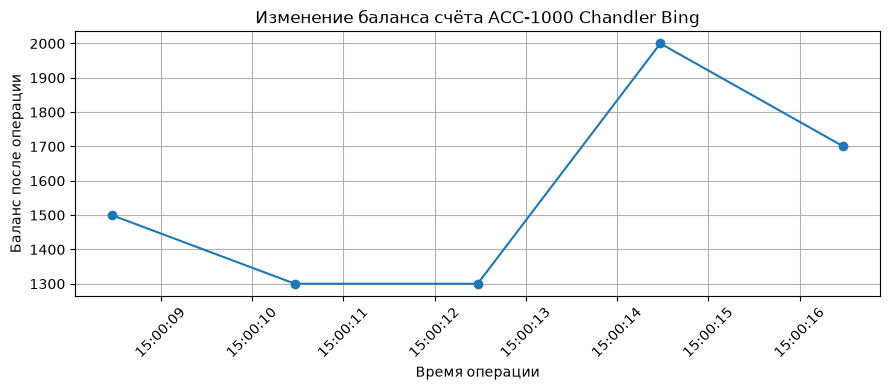

In [7]:
acc.plot_balance()

## Задание 2. Разные типы счетов и аналитика

In [8]:
class SavingsAccount(BankAccount):
    account_type = "savings"
    allowed_types = ["deposit", "withdraw", "interest"]

    #ограничение на снятие больше 50%
    def can_withdraw(self, amount):
        return amount <= self.balance * 0.5
    
    #начисление процентов
    def add_interest(self, rate):
        if not isinstance(rate, (int, float)) or rate <= 0:
            raise ValueError("Процентная ставка должна быть положительным числом")
        interest = round(self.balance * rate / 100, 2)
        self.balance = round(self.balance + interest, 2)
        self._add_record("interest", interest, "success")
        return interest

## Проверка задание 2

**2.1 Создаём расчётный и сберегательный счета:**

In [9]:
checking = BankAccount("Моника Геллер", 7000)        
savings = SavingsAccount("Joe Tribiani", 10000)    
print(checking)
print(savings)
print("Тип первого:", checking.account_type, "| тип второго:", savings.account_type)

ACC-1001 | checking | Моника Геллер | баланс: 7000
ACC-1002 | savings | Joe Tribiani | баланс: 10000
Тип первого: checking | тип второго: savings


**2.2 Начисление процентов и запрет снятия больше 50%:**

In [10]:
interest = savings.add_interest(10)
print("Начислено процентов (процентная ставка 10%):", interest, "| баланс:", savings.get_balance())

#отклонение снятия
result = savings.withdraw(6000)      
print("Клиент хочет снять 6000, операция пройдет?", result, "| баланс:", savings.get_balance())

#успешное снятие
result = savings.withdraw(5000)      
print("Клиент хочет снять 5000, операция пройдет?", result, "| баланс:", savings.get_balance())

display(savings.get_history())

Начислено процентов (процентная ставка 10%): 1000.0 | баланс: 11000.0
Клиент хочет снять 6000, операция пройдет? False | баланс: 11000.0
Клиент хочет снять 5000, операция пройдет? True | баланс: 6000.0


,type,amount,datetime,balance_after,status,transfer_id
0,interest,1000.0,2026-10-21 15:00:16.642044,11000.0,success,None
1,withdraw,6000.0,2026-10-21 15:00:16.642103,11000.0,fail,None
2,withdraw,5000.0,2026-10-21 15:00:16.642140,6000.0,success,None


**2.3 Последние N крупных операций**

In [11]:
checking.deposit(100)
checking.deposit(1500)
checking.withdraw(50)
checking.deposit(700)
checking.withdraw(99999)     
checking.withdraw(900)

print("Вся история:")
display(checking.get_history())

print("Последние 2 успешные операции от 500:")
display(checking.last_big_operations(500, 2))

Вся история:


,type,amount,datetime,balance_after,status,transfer_id
0,deposit,100,2026-10-21 15:00:16.647164,7100,success,None
1,deposit,1500,2026-10-21 15:00:16.647178,8600,success,None
2,withdraw,50,2026-10-21 15:00:16.647190,8550,success,None
3,deposit,700,2026-10-21 15:00:16.647199,9250,success,None
4,withdraw,99999,2026-10-21 15:00:16.647209,9250,fail,None
5,withdraw,900,2026-10-21 15:00:16.647217,8350,success,None


Последние 2 успешные операции от 500:


,type,amount,datetime,balance_after,status,transfer_id
0,deposit,700,2026-10-21 15:00:16.647199,9250,success,None
1,withdraw,900,2026-10-21 15:00:16.647217,8350,success,None


**2.4 Проверка некоректных данных**

In [12]:
print("- Некорректные имена -")
for name in ["filipp kirkorov", "Филя", "Filipp Kirkorov King", "Filipp Kirkorov1", "ФИЛИППИЩЕ КИРКОРОВ", 65894]:
    try:
        BankAccount(name)
        print(name, "-> принято")
    except ValueError as e:
        print(name, "-> ОШИБКА:", e)

print()
print("- Некорректный начальный баланс -")
try:
    BankAccount("Ivan Petrov", -500)
except ValueError as e:
    print("ОШИБКА:", e)

print()
print("- Некорректные суммы -")
for bad in [-100, 0, "100", None]:
    try:
        checking.deposit(bad)
        print(bad, "-> принято")
    except ValueError as e:
        print(bad, "-> ОШИБКА:", e)

print()
print("Баланс не изменился:", checking.get_balance())

- Некорректные имена -
filipp kirkorov -> ОШИБКА: Имя владельца должно быть в формате 'Имя Фамилия' (с заглавных букв)
Филя -> ОШИБКА: Имя владельца должно быть в формате 'Имя Фамилия' (с заглавных букв)
Filipp Kirkorov King -> ОШИБКА: Имя владельца должно быть в формате 'Имя Фамилия' (с заглавных букв)
Filipp Kirkorov1 -> ОШИБКА: Имя владельца должно быть в формате 'Имя Фамилия' (с заглавных букв)
ФИЛИППИЩЕ КИРКОРОВ -> ОШИБКА: Имя владельца должно быть в формате 'Имя Фамилия' (с заглавных букв)
65894 -> ОШИБКА: Имя владельца должно быть в формате 'Имя Фамилия' (с заглавных букв)

- Некорректный начальный баланс -
ОШИБКА: Начальный баланс не может быть отрицательным

- Некорректные суммы -
-100 -> ОШИБКА: Сумма должна быть положительным числом
0 -> ОШИБКА: Сумма должна быть положительным числом
100 -> ОШИБКА: Сумма должна быть положительным числом
None -> ОШИБКА: Сумма должна быть положительным числом

Баланс не изменился: 8350


## Перевод между счетами

In [13]:
print("До перевода:  расчётный =", checking.get_balance(), "| сберегательный =", savings.get_balance())

#Перевод с расчетного на сберегательный, денег достаточно
ok1 = checking.transfer(savings, 400)  
print("Перевод 400 расчётный -> сберегательный:", ok1)

#Перевод со сберегательно на расчетный, превышение 50% лимита, отказ
ok2 = savings.transfer(checking, 4000)  
print("Перевод 4000 сберегательный -> расчётный:", ok2)

print("После:        расчётный =", checking.get_balance(), "| сберегательный =", savings.get_balance())

print()
print("История расчётного (колонка transfer_id):")
display(checking.get_history().tail(4))
print("История сберегательного:")
display(savings.get_history().tail(4))

До перевода:  расчётный = 8350 | сберегательный = 6000.0
Перевод 400 расчётный -> сберегательный: True
Перевод 4000 сберегательный -> расчётный: False
После:        расчётный = 7950 | сберегательный = 6400.0

История расчётного (колонка transfer_id):


,type,amount,datetime,balance_after,status,transfer_id
3,deposit,700,2026-10-21 15:00:16.647199,9250,success,NaN
4,withdraw,99999,2026-10-21 15:00:16.647209,9250,fail,NaN
5,withdraw,900,2026-10-21 15:00:16.647217,8350,success,NaN
6,withdraw,400,2026-10-21 15:00:16.658981,7950,success,TR-1


История сберегательного:


,type,amount,datetime,balance_after,status,transfer_id
1,withdraw,6000.0,2026-10-21 15:00:16.642103,11000.0,fail,NaN
2,withdraw,5000.0,2026-10-21 15:00:16.642140,6000.0,success,NaN
3,deposit,400.0,2026-10-21 15:00:16.658988,6400.0,success,TR-1
4,withdraw,4000.0,2026-10-21 15:00:16.659022,6400.0,fail,TR-2
